# Fase 0 - Análisis de magnitud-frecuencia del inventario 

La función de este Notebook es completar la fase 0 tras la generación del inventario. 

**¿Que hace?**

Ajusta la distribución gamma inversa de tres parámetros de Malamud et al. (2004) a las áreas de los movimientos en masa del inventario. Marca el Rollover o Punto de quiebre ($A_r$) y se usa como  el área mínima a partir de la cual el inventario se considera completo.

Como en este trabajo se usaron dos grupos de fuente de información para el inventario, El ajuste se hace por separado para los dos procesos de detección porque cada uno registra los eventos de manera distinta.La curva del inventario integrado se calcula como referencia.  

El código hace el análisis dos veces:

1. Corrida principal: usa todas las áreas. De aquí se derivan los umbrales de completitud.
2. Corrida de sensibilidad: descarta en cada grupo el 5 % de los eventos más pequeños y repite el ajuste, para medir cuánto se mueve el rollover.


#### **Datos de entrada**

| Elemento | Descripción | 
|---|---|
| `Inventario_integrado` | Es la capa de polígonos del inventario completo , en una geodatabase de archivo y en un sistema de coordenadas proyectado en metros.  | 
| Campo `Shape_Area` | Área calculada de cada polígono en $m^{2}$ Se calcula y actualiza automaticamente en ArcGIS | 
| Campo `fuente` | Es la columna donde se agrupan las fuentes en los tipos de fuente a los que ajustará la curva|


Las **salidas** son varias entre las que se encuentran los histogramas logaritmicos de cada grupo: límites de cada intervalo, número de eventos y densidad, los parámetros de cada ajuste, el rollover, exponente de la cola y avisos de control de calidad de cada grupo, las figuras con las curvas graficadas en dos panles de comparación. 

#### **¿Cómo reproducirlo?**

Este código fue creado en Notebooks de ArcGIS PRO, por lo que se sugiere su uso dentro del software, el proyecto debe contener la capa con el inventario integrado.

1. Cambiar la carpeta de salida n la celda 3 por la carpeta donde se quieren guardar los resultados. Si no existe, el notebook la crea.
2. Ejecutar todas las celdas en orden, de arriba hacia abajo. 


In [52]:
### Modulo de rutas, escritura de archivos csv y control de texto ####
import os
import csv
import unicodedata

### Modulo de librerias de análisis matematico y estadistico ####
import numpy as np
import arcpy
from scipy import stats
from scipy.special import gamma as funcion_gamma


### Modulo de generación de graficos ####
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

## CONFIGURACIÓN 

Esta celda reúne  en un solo lugar todos los parámetros que se pueden cambiar.

`Grupo` es un diccionario de Python. Sus claves son los nombres de los grupos, que después aparecen en las tablas y en la figura, y sus valores son listas con los textos del campo fuente que pertenecen a cada grupo.

Está dividido en tres bloques: 
1. **UMBRAL DE ÁREA MINIMA** asígna tres opciones a la varriable `MODO_AREA_MINIMA` según el criterio que se quiera usar estos son:

* "ninguno": No hace ningún filtro de área minima, usa todos los datos
* "fijo":usa `AREA_MINIMA_FIJA` bajo el un criterio de resolucion / escala
* "percentil": descarta el `PCT_DESCARTADO` % de eventos mas pequenos

2. Genera los parámetros de las curvas ajustadas ya sea si se calculas o se fijan $\rho$, $s$ y $a$
3. Genera tres valores de control calidad para los parametros calculados y los ajustes resultantes


In [53]:
# =========================== CONFIGURACION ===========================


CAPA = "Inventario_integrado"
 
CAMPO_AREA   = "Shape_Area"
CAMPO_FUENTE = "fuente"
 
GRUPOS = {
    "Mapeo sobre imagenes": ["Propia (GoogleEarth)", "Propia (PlanetScope)"],
    "Registros institucionales": ["DAGRD", "SIATA", "SIMMA", "DAGRD (SIRE)", "DAGRD Medellín", "DRAGAN",
                                 "Geohazards", "Fotointerpretación","SIRMED" ],
}
 
CARPETA_SALIDA = r"D:\Users\tasal\Desktop\Tesis de grado\fase0_prueba"


# ---- 1) UMBRAL DE AREA MINIMA --------------------------------------


MODO_AREA_MINIMA = "ninguno"

AREA_MINIMA_FIJA = 10.0
PCT_DESCARTADO   = 5.0      
UMBRAL_POR_GRUPO = True

# ---- 2) CURVA DEL INVENTARIO INTEGRADO  --------------------------------------
INCLUIR_CURVA_GLOBAL = True
NOMBRE_CURVA_GLOBAL  = "Inventario integrado"


CONFIG_DEFECTO = {"rho_fijo": None, "factor_cola": 3.0}

CONFIG_GRUPO = {}

# ---- 3) CONTROL DE CALIDAD -----------------------------------------

SIGMAS_BETA = 2.0                          # aviso si |beta-(rho+1)| supera este n de sigmas
EXP_COLA_MIN, EXP_COLA_MAX = 2.11, 2.48    # intervalo publicado para rho+1
                                           # Malamud et al. (2004); Stark y Hovius (2001)
RHO_RESPALDO = 1.40                        # valor impuesto cuando el ajuste libre da rho <= 1

### Resolución del histograma curvas de referencia y funciones auxiliares

Esta es la segunda parte de las configuraciones

**¿Qué hace?**

Fija cuántos intervalos tiene el histograma por cada década de área, guarda los parámetros de dos curvas publicadas para dibujarlas como referencia y define dos funciones que usan las celdas siguientes: `normalizar`, para comparar textos, y `pdf_gamma_inversa`, para evaluar la curva ajustada.

`BINS_POR_DECADA` = 6: número de intervalos del histograma por cada factor de 10 en el área. Cada intervalo cubre 1/6 de década, así que su límite superior es unas 1,47 veces el inferior.
`IMPRIMIR_TABLA` = False: con True, la celda 12 muestra en pantalla la tabla de densidad de cada grupo.


`REFERENCIAS` guarda los parámetros de dos curvas publicadas. 

| Curva | $rho$ | $a (m^{2})$| $s (m^{2})$|
|---|---|---|---|
| Malamud et al. (2004) | 1,40  |1280 |−132|
| AMVA (Aristizábal et al., 2019b) | 1,70 | 450|−47|

#### **Funciones**

`normalizar(texto)` prepara un texto para compararlo sin que importen las tildes, las mayúsculas ni los espacios en los extremos.

`pdf_gamma_inversa(A, rho, a, s)` calcula la densidad de probabilidad de la gamma inversa de tres parámetros de Malamud et al. (2004):

$$p(A) = \frac{1}{a\,\Gamma(\rho)} \left[\frac{a}{A-s}\right]^{\rho+1} \exp\left[-\frac{a}{A-s}\right]$$

**Esta función solo se usa para dibujar las curvas en la figura; el ajuste se realiza con scipy en la celda 8.**

In [54]:

BINS_POR_DECADA = 6
IMPRIMIR_TABLA = False     # Si es TRUE muestra la tabla de densidad en consola



REFERENCIAS = {
    "Malamud et al. (2004)": dict(rho=1.40, a=1.28e-3 * 1e6, s=-1.32e-4 * 1e6),
    "AMVA (Aristizabal et al. 2019b)": dict(rho=1.70, a=0.00045 * 1e6, s=-0.000047 * 1e6),
}
ESTILO_REF = {
    "Malamud et al. (2004)":     dict(color="orange", lw=1, ls="--"),
    "AMVA (Aristizabal et al. 2019b)": dict(color="green", lw=1, ls="--"),
}

def normalizar(texto):
    t = unicodedata.normalize("NFD", str(texto))
    t = "".join(c for c in t if unicodedata.category(c) != "Mn")
    return t.lower().strip()
 
 
def pdf_gamma_inversa(A, rho, a, s):
    """Gamma Inversa de tres parametros de Malamud et al. (2004)."""
    u = np.asarray(A, dtype=float) - s
    return (1.0 / (a * funcion_gamma(rho))) * (a / u) ** (rho + 1) * np.exp(-a / u)

### Lectura de datos desde la capa

**¿Que hace?**

La función `leer_datos_crudos` recorre la tabla de atributos de la capa y devuelve las áreas separadas por grupo. Avisa cuántos registros tienen el campo de área vacío y qué valores del campo `fuente` no están en el diccionario `GRUPOS`.




In [55]:
def leer_datos_crudos():
    campo_geom = "SHAPE@AREA" if CAMPO_AREA is None else CAMPO_AREA
    campos = [campo_geom, CAMPO_FUENTE]
 
    mapa = {}
    for grupo, valores in GRUPOS.items():
        for v in valores:
            mapa[normalizar(v)] = grupo
 
    datos = {g: [] for g in GRUPOS}
    sin_clasificar, nulos = {}, 0
 
    with arcpy.da.SearchCursor(CAPA, campos) as cur:
        for area, fuente in cur:
            if area is None:
                nulos += 1
                continue
            clave = normalizar(fuente) if fuente is not None else ""
            grupo = mapa.get(clave)
            if grupo is None:
                sin_clasificar[fuente] = sin_clasificar.get(fuente, 0) + 1
                continue
            datos[grupo].append(float(area))
 
    print("Registros con area nula: {}".format(nulos))
    if sin_clasificar:
        print("\n*** VALORES DEL CAMPO FUENTE SIN CLASIFICAR ***")
        for v, n in sorted(sin_clasificar.items(), key=lambda x: -x[1]):
            print("   {!r}  ->  {} registros".format(v, n))
        print("Agregalos a GRUPOS. Quedan FUERA de todas las curvas,")
        print("incluida la del inventario completo.\n")
 
    return {g: np.array(v) for g, v in datos.items() if len(v) > 0}

### Umbrales de área mínima 

**¿Que hace?**

Define y aplica el área mínima de cada grupo según el modo (ninguno,fijo o percentil) de la corrida, y une los grupos en la curva del inventario integrado.


Se divide en tres funciones: 

* `calcular_umbrales(datos, modo=None)` Devuelve un diccionario con un umbral en m² por grupo.
* `aplicar_umbrales(datos, umbrales, modo=None)` Conserva en cada grupo las áreas mayores o iguales al umbral. La comparación da un arreglo de verdadero o falso y solo quedan las posiciones verdaderas. Imprime cuántos eventos conserva cada grupo y qué porcentaje representan.
* `agregar_curva_global(datos, umbrales)` Se activa si al variable `INCLUIR_CURVA_GLOBAL` es TRUE y hay al menos dos grupos, une las áreas ya filtradas de todos los grupos en un grupo nuevo, "Inventario integrado". 

In [56]:
def calcular_umbrales(datos, modo=None):
    """Devuelve un diccionario grupo -> umbral de area minima en m2."""
    if modo is None:
        modo = MODO_AREA_MINIMA

    if modo == "ninguno":
        return {g: 0.0 for g in datos}

    if modo == "fijo":
        return {g: AREA_MINIMA_FIJA for g in datos}

    if modo != "percentil":
        raise ValueError("modo debe ser 'ninguno', 'fijo' o 'percentil'")

    if PCT_DESCARTADO > 50:
        print("\n*** AVISO: PCT_DESCARTADO = {:.0f} descarta mas de la mitad".format(
            PCT_DESCARTADO))

    if UMBRAL_POR_GRUPO:
        return {g: float(np.percentile(a, PCT_DESCARTADO)) for g, a in datos.items()}

    todas = np.concatenate(list(datos.values()))
    u = float(np.percentile(todas, PCT_DESCARTADO))
    return {g: u for g in datos}
 
 
def aplicar_umbrales(datos, umbrales, modo= None):
    if modo is None:
        modo = MODO_AREA_MINIMA
    filtrados = {}
    print("\nUMBRAL DE AREA MINIMA  (modo: {})".format(modo))
    for g, areas in datos.items():
        u = umbrales[g]
        nuevas = areas[areas >= u]
        print("  {:<28} umbral {:>9.1f} m2   conserva {}/{} ({:.1f} %)".format(
            g, u, len(nuevas), len(areas), 100.0 * len(nuevas) / len(areas)))
        if len(nuevas) > 0:
            filtrados[g] = nuevas
    return filtrados
 
 
def agregar_curva_global(datos, umbrales):
    """Une todos los grupos ya filtrados en una sola poblacion."""
    if not INCLUIR_CURVA_GLOBAL or len(datos) < 2:
        return datos, umbrales
    datos[NOMBRE_CURVA_GLOBAL] = np.concatenate(list(datos.values()))
    umbrales[NOMBRE_CURVA_GLOBAL] = min(umbrales[g] for g in umbrales if g in datos)
    return datos, umbrales

### Histograma logarítmico y densidad de frecuencia

**¿Que hace?**

la función `densidad_frecuencia(areas)` construye el histograma de las áreas con intervalos espaciados en escala logarítmica y lo convierte en densidad de probabilidad, la forma en que Malamud et al. (2004) presentan las curvas de magnitud–frecuencia.

Al final, la función devuelve un diccionario con los límites, centros, conteos, anchos, densidades y el total de eventos.

In [57]:
def densidad_frecuencia(areas, bins_por_decada=BINS_POR_DECADA):
    a_min, a_max = areas.min(), areas.max()
    decadas = np.log10(a_max) - np.log10(a_min)
    n_bins = max(int(np.ceil(decadas * bins_por_decada)), 4)
    bordes = np.logspace(np.log10(a_min), np.log10(a_max), n_bins + 1)
 
    conteo, _ = np.histogram(areas, bins=bordes)
    ancho = np.diff(bordes)
    centro = np.sqrt(bordes[:-1] * bordes[1:])
    densidad = conteo / (len(areas) * ancho)
 
    return dict(bordes=bordes, centro=centro, conteo=conteo,
                ancho=ancho, densidad=densidad, n_total=len(areas))

### Ajuste de la gamma inversa y exponente de la cola

**¿Que hace?**

Se divide en dos funciones: 

* La función `ajustar` estima $\rho$, $a$ y $s$ por máxima verosimilitud y calcula el rollover. Depende de **scipy** para escribir la gamma inversa con tres parámetros (forma, posición y ecala ).El ajuste es una optimización numérica que no usa números aleatorios: con los mismos datos da siempre el mismo resultado.
* La función `exponente_cola` estima la pendiente de la cola sin usar la gamma inversa, para comprobar si el ajuste la describe bien. Si la gamma inversa describe bien la cola, `beta` debería parecerse a $\rho + 1$. Esta funsión devuelve tambíen el error y el número de eventos en la cola 

In [58]:
def ajustar(areas, rho_fijo=None):
    """MLE. scipy entrega (forma, loc, scale) = (rho, s, a).
    Siempre estima rho libre primero y solo lo fija si el ajuste libre da
    rho <= 1, region donde la media a/(rho-1)+s diverge."""
    rho_libre, s, a = np.nan, np.nan, np.nan
    try:
        rho_libre, s, a = stats.invgamma.fit(areas)
    except Exception as e:
        print("   Ajuste libre fallido ({}).".format(e))

    fijar = rho_fijo if rho_fijo is not None else (
        RHO_RESPALDO if (np.isnan(rho_libre) or rho_libre <= 1.0) else None)

    if fijar is None:
        rho = rho_libre
        forzado = False
    else:
        rho, s, a = stats.invgamma.fit(areas, f0=fijar)
        forzado = True

    rollover = s + a / (rho + 1.0)
    return rho, a, s, rollover, forzado, rho_libre
 
 
def exponente_cola(areas, a_min):
    """Estimador de Hill del exponente de la ley de potencia."""
    cola = areas[areas >= a_min]
    if len(cola) < 20:
        return np.nan, len(cola), np.nan
    beta = 1.0 + len(cola) / np.sum(np.log(cola / a_min))
    error = (beta - 1.0) / np.sqrt(len(cola))      # error estandar aproximado
    return beta, len(cola), error

### Control de calidad del ajuste

**¿Que hace?**

 La función `revisar_calidad` revisa los resultados por grupo y devuelve una lista de avisos en texto.  Los avisos se imprimen al finalizar la corrida y se guardan en un csv.

Estas son los puntos que revisa: 

* $\beta$ no se pudo estimar porque la cola tiene menos de 20 eventos.
* Si $\rho$ no fue impuesto: la diferencia entre $\beta$ y $\rho + 1$ supera el valor definido en `SIGMA_BETA` interpretado como errores estándar de $\beta$. El aviso dice si la cola observada es más pesada que la del ajuste.
* La cola reúne más del 50 % de la muestra. Con un corte tan bajo, $\beta$  mide el cuerpo de la distribución y no la cola.
*  Si $\rho$  fue impuesto, deja un aviso para declararlo. Si no lo fue y $\rho + 1$ queda fuera del intervalo publicado genera un aviso.
*  El valor absoluto de $s$  es mayor que el rollover: señal de que $s$ está compensando otra cosa en lugar de solo desplazar la curva.
*  El rollover está a menos de 1,2 veces el umbral de área mínima: el máximo podría ser producto del recorte y no de los datos.
*  El rollover cae fuera del rango de áreas observadas.


In [59]:
def revisar_calidad(rho, rho_libre, s, rollover, beta, err, n_cola, frac_cola,
                    umbral, areas, forzado):
    avisos = []

    if np.isnan(beta):
        avisos.append("La cola tiene solo {} eventos: beta no se pudo estimar. "
                      "Reporta unicamente la curva empirica.".format(n_cola))
    elif not forzado:
        d = beta - (rho + 1.0)
        if abs(d) / err > SIGMAS_BETA:
            avisos.append(
                "beta = {:.3f} difiere de rho+1 = {:.3f} en {:.1f} sigma: la cola "
                "observada es mas {} que la del ajuste.".format(
                    beta, rho + 1.0, abs(d) / err, "pesada" if d < 0 else "ligera"))

    if frac_cola > 0.5:
        avisos.append("La cola abarca el {:.0f} % de la muestra: con ese corte beta no "
                      "estima la cola. Sube factor_cola.".format(100.0 * frac_cola))

    if forzado:
        avisos.append("El ajuste libre dio rho = {:.3f} <= 1, region donde la media "
                      "a/(rho-1)+s diverge. Se impuso rho = {:.3f} (Malamud et al., 2004) "
                      "y se estimaron solo a y s.".format(rho_libre, rho))
    elif not (EXP_COLA_MIN <= rho + 1.0 <= EXP_COLA_MAX):
        avisos.append("El exponente de cola del ajuste, rho+1 = {:.3f}, queda fuera del "
                      "intervalo publicado ({}-{}).".format(
                          rho + 1.0, EXP_COLA_MIN, EXP_COLA_MAX))

    if abs(s) > rollover:
        avisos.append("|s| = {:.1f} supera el rollover ({:.1f}): s esta compensando "
                      "algo en lugar de desplazar la curva.".format(abs(s), rollover))

    if rollover < 1.2 * umbral:
        avisos.append("El rollover ({:.1f} m2) esta pegado al umbral de area minima "
                      "({:.1f} m2): puedes estar midiendo tu propio filtro.".format(
                          rollover, umbral))

    if rollover > areas.max() or rollover < areas.min():
        avisos.append("El rollover cae fuera del rango de los datos.")

    return avisos

### Creación y exportación de tablas y figuras 

**¿Que hace?**
Se divide en siete funciones. 

`imprimir_tabla(grupo, t)`, `exportar_tabla(resultados, ruta)` y `exportar_parametros(resultados, ruta)` son las funciones encargadas de mostrar y guardar los resultados en tablas . Los CSV usan punto y coma como separador y la codificación utf-8-sig (UTF-8 con una marca inicial), para que Excel separe bien las columnas y muestre las tildes. 

El otro grupo de funciones se encargan de crear y dibujar la curva de magnitud–frecuencia y arma la figura final de dos paneles. 

In [60]:
def imprimir_tabla(grupo, t):
    print("\n  TABLA DE DENSIDAD - {}".format(grupo))
    print("  {:>12} {:>12} {:>12} {:>7} {:>14}".format(
        "A_inf", "A_sup", "A_centro", "N", "Densidad"))
    print("  " + "-" * 61)
    for i in range(len(t["conteo"])):
        print("  {:>12.1f} {:>12.1f} {:>12.1f} {:>7d} {:>14.3e}".format(
            t["bordes"][i], t["bordes"][i + 1], t["centro"][i],
            int(t["conteo"][i]), t["densidad"][i]))
 
 
def exportar_tabla(resultados, ruta):
    with open(ruta, "w", newline="", encoding="utf-8-sig") as f:
        w = csv.writer(f, delimiter=";")
        w.writerow(["Grupo", "A_inf_m2", "A_sup_m2", "A_centro_m2",
                    "N_eventos", "Ancho_m2", "Densidad_m-2"])
        for grupo, r in resultados.items():
            t = r["tabla"]
            for i in range(len(t["conteo"])):
                w.writerow([grupo,
                            "{:.2f}".format(t["bordes"][i]),
                            "{:.2f}".format(t["bordes"][i + 1]),
                            "{:.2f}".format(t["centro"][i]),
                            int(t["conteo"][i]),
                            "{:.2f}".format(t["ancho"][i]),
                            "{:.6e}".format(t["densidad"][i])])
    print("Tabla de densidad    -> {}".format(ruta))
    
 
def exportar_parametros(resultados, ruta):
    with open(ruta, "w", newline="", encoding="utf-8-sig") as f:
        w = csv.writer(f, delimiter=";")
        w.writerow(["Grupo", "Umbral_m2", "N_eventos", "rho", "Rho_libre",
                    "Rho_impuesto", "a_m2", "s_m2",
                    "Rollover_m2", "Beta_cola", "Error_beta", "N_cola",
                    "Dif_beta_rho1", "Eventos_bajo_rollover",
                    "Pct_bajo_rollover", "N_avisos", "Avisos", "Rho_fijo", "Factor_cola"])
        for grupo, r in resultados.items():
            dif = "" if (np.isnan(r["beta"]) or r["forzado"]) else "{:.3f}".format(
                abs(r["beta"] - (r["rho"] + 1.0)))
            w.writerow([grupo,
                        "{:.2f}".format(r["umbral"]), r["n"],
                        "{:.4f}".format(r["rho"]),
                        "" if np.isnan(r["rho_libre"]) else "{:.4f}".format(r["rho_libre"]),
                        "si" if r["forzado"] else "no",
                        "{:.2f}".format(r["a"]),
                        "{:.2f}".format(r["s"]),
                        "{:.2f}".format(r["rollover"]),
                        "" if np.isnan(r["beta"]) else "{:.3f}".format(r["beta"]),
                        "" if np.isnan(r["err"]) else "{:.3f}".format(r["err"]),
                        r["n_cola"], dif, r["n_bajo"],
                        "{:.1f}".format(r["pct_bajo"]),
                        len(r["avisos"]), " | ".join(r["avisos"]),
                        r["rho_fijo"], r["factor_cola"]])
    print("Parametros y avisos  -> {}".format(ruta))


def exportar_tabla_tesis(comparacion, ruta):
    ppal, sens = MODOS_A_CORRER[0], MODOS_A_CORRER[-1]
    with open(ruta, "w", newline="", encoding="utf-8-sig") as f:
        w = csv.writer(f, delimiter=";")
        w.writerow(["Grupo", "N", "Mediana_m2", "A_max_m2", "rho", "rho_libre",
                    "rho_impuesto", "a_m2", "s_m2", "Ar_m2", "Ar_recorte_m2",
                    "beta", "sigma_beta", "n_cola", "Eventos_bajo_Ar", "Pct_bajo_Ar"])
        for g, r in comparacion[ppal].items():
            rs = comparacion[sens].get(g)
            w.writerow([g, r["n"],
                        "{:.1f}".format(r["mediana"]), "{:.1f}".format(r["a_max"]),
                        "{:.3f}".format(r["rho"]),
                        "" if np.isnan(r["rho_libre"]) else "{:.3f}".format(r["rho_libre"]),
                        "si" if r["forzado"] else "no",
                        "{:.1f}".format(r["a"]), "{:.1f}".format(r["s"]),
                        "{:.1f}".format(r["rollover"]),
                        "" if rs is None else "{:.1f}".format(rs["rollover"]),
                        "" if np.isnan(r["beta"]) else "{:.3f}".format(r["beta"]),
                        "" if np.isnan(r["err"]) else "{:.3f}".format(r["err"]),
                        r["n_cola"], r["n_bajo"], "{:.1f}".format(r["pct_bajo"])])
    print("Tabla de la tesis    -> {}".format(ruta))
 


# quedan en unos 9 puntos en el documento.
TAMANO_LETRA_PANEL = 18
LEYENDA_EN_AMBOS = True  # False: leyenda solo en (a). La de (b) muestra el A_r
                         # con el recorte del 5 %, que también está en la Tabla 1.
 
 
def dibujar_panel(ax, resultados, con_leyenda=True, letra=None):
    colores = ["#1f77b4", "#d62728", "#2ca02c", "#9467bd"]
    rejilla = np.logspace(0.5, 6, 400)
    colores_grupo = {}
 
    i = 0
    for grupo, r in resultados.items():
        global_ = (grupo == NOMBRE_CURVA_GLOBAL)
        c = "0.40" if global_ else colores[i % len(colores)]
        colores_grupo[grupo] = c
        marca = "s" if global_ else "o"
        if not global_:
            i += 1
 
        t = r["tabla"]
        m = t["densidad"] > 0
        ax.loglog(t["centro"][m], t["densidad"][m], marca, color=c, ms=3,
                  mfc="none" if global_ else c)
        a_ini = max(t["bordes"][0], r["s"] + 1e-6)
        a_fin = t["bordes"][-1]
        obs = np.logspace(np.log10(a_ini), np.log10(a_fin), 300)
        ext = np.logspace(np.log10(a_fin), 6, 120)
        ax.loglog(obs, pdf_gamma_inversa(obs, r["rho"], r["a"], r["s"]),
                  "-", color=c, lw=1.8, alpha=0.9)
        ax.loglog(ext, pdf_gamma_inversa(ext, r["rho"], r["a"], r["s"]),
                  ":", color=c, lw=1.2, alpha=0.55)
        ax.axvline(r["rollover"], color=c, ls=":", lw=1.1)
 
    for nombre, p in REFERENCIAS.items():
        e = ESTILO_REF[nombre]
        ax.loglog(rejilla, pdf_gamma_inversa(rejilla, p["rho"], p["a"], p["s"]),
                  color=e["color"], lw=e["lw"], ls=e["ls"])
 
    if con_leyenda:
        entradas = [
            Line2D([], [], color="none", marker="o", mfc="black", ms=3.5,
                   label=u"Puntos: Intervalos de densidad por grupo"),
            Line2D([], [], color="0.2", lw=1.6,
                   label=u"Línea: gamma inversa ajustada"),
            Line2D([], [], color="none", label=" "),
        ]
        for g, r in resultados.items():
            entradas.append(Line2D([], [], color=colores_grupo[g], lw=2.2,
                                   label=u"{}  —  $A_r$ = {:.0f} m²".format(
                                       g, r["rollover"])))
        entradas.append(Line2D([], [], color="none", label=" "))
        for nombre in REFERENCIAS:
            e = ESTILO_REF[nombre]
            entradas.append(Line2D([], [], color=e["color"], lw=e["lw"],
                                   ls=e["ls"], label=nombre))
        ax.legend(handles=entradas, fontsize=7, loc="lower left", framealpha=0.9)
 
    ax.set_xlabel(u"Área del movimiento en masa, $A_L$ [m$^2$]")
    ax.set_ylabel(u"Densidad de probabilidad, $p(A_L)$ [m$^{-2}$]")
    ax.grid(True, which="both", ls=":", lw=0.4, alpha=0.6)
 
    if letra:
        ax.text(0.975, 0.975, letra, transform=ax.transAxes, ha="right", va="top",
                fontsize=TAMANO_LETRA_PANEL, fontweight="bold", zorder=10,
                bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
 
 
def graficar(resultados, ruta):
    fig, ax = plt.subplots(figsize=(8.5, 6.5))
    dibujar_panel(ax, resultados)
    fig.tight_layout()
    fig.savefig(ruta, dpi=300)
    plt.show()
 
 
def graficar_comparacion(comparacion, ruta):
    letras = {"ninguno": u"(a)", "percentil": u"(b)"}
    modos = list(comparacion.keys())
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.8), sharex=True, sharey=True)
    for k, (ax, m) in enumerate(zip(axes, modos)):
        dibujar_panel(ax, comparacion[m],
                      con_leyenda=LEYENDA_EN_AMBOS or (k == 0),
                      letra=letras.get(m, u"({})".format("ab"[k])))
    axes[1].set_ylabel("")
    fig.tight_layout()
    fig.savefig(ruta, dpi=300)
    plt.show()
    print(u"Figura de dos paneles -> {}".format(ruta))

### Corrida principal, manejo de impresiones y exportaciones 

**¿Que hace?**

Ejecuta todo el análisis con las funciones anteriores: lee la capa, ajusta las curvas de los tres grupos en las dos corridas, imprime los resultados y los avisos, guarda las tablas y genera la figura.

1. Crea una carpeta de salida en caso de no definirla
2. corre dos opciones en caso de validar como cambian las curvas con diferentes podos
3. lee la capa del inventario
4. Para cada modo:


* calcula y aplica los umbrales de área mínima y agrega la curva del inventario integrado
* y para cada grupo: imprime el número de eventos, el área mínima, la mediana y la máxima, y avisa si hay menos de 30 eventos;
calcula el histograma, el inicio de la cola, el exponente de la cola, la fracción de la muestra que queda en la cola y el número de eventos bajo el rollover; imprime los resultados.




Registros con area nula: 0

######################################################################
### CORRIDA CON MODO DE UMBRAL: ninguno
######################################################################

UMBRAL DE AREA MINIMA  (modo: ninguno)
  Mapeo sobre imagenes         umbral       0.0 m2   conserva 302/302 (100.0 %)
  Registros institucionales    umbral       0.0 m2   conserva 151/151 (100.0 %)

GRUPO: Mapeo sobre imagenes   (302 eventos)   [modo: ninguno]
  Umbral aplicado:         0.0 m2
  Factor de cola: 3.0
  Area minima  :         29.9 m2
  Mediana      :       1180.0 m2
  Area maxima  :      53356.0 m2
  rho = 1.335
  a = 1320.2 m2   s = -162.2 m2
  PUNTO DE QUIEBRE (rollover): 403.1 m2
  Exponente de cola rho+1    : 2.335  (dentro del intervalo publicado 2.11-2.48)
  Cola: A >= 3 x Ar = 1209.2 m2   n = 148 (49 % de la muestra)
  Exponente de la cola beta  : 2.018 +/- 0.084
  beta - (rho+1)             : -0.318  =  3.8 sigma
  Eventos bajo el quiebre    : 50 de 302 (1

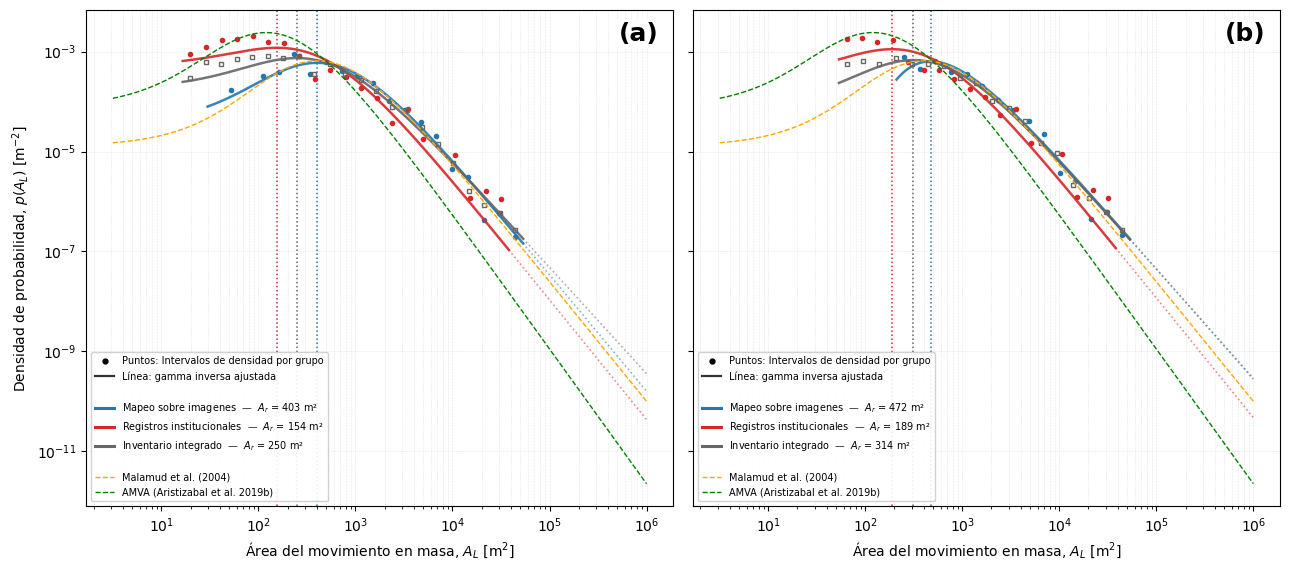

Figura de dos paneles -> D:\Users\tasal\Desktop\Tesis de grado\fase0_prueba\figura1_magnitud_frecuencia.png
------------------------------------------------------------------------------
Ancho de un intervalo del histograma: 0.167 decadas (47 %).
Desplazamientos menores quedan dentro de la resolucion del analisis.


In [61]:
if not os.path.isdir(CARPETA_SALIDA):
    os.makedirs(CARPETA_SALIDA)
    

MODOS_A_CORRER = ["ninguno", "percentil"]

crudos = leer_datos_crudos()
comparacion = {}

GRAFICAR_POR_MODO = False    # figuras individuales; la de dos paneles se genera aparte
for modo in MODOS_A_CORRER:
    print("\n" + "#" * 70)
    print("### CORRIDA CON MODO DE UMBRAL: {}".format(modo))
    print("#" * 70)

    umbrales = calcular_umbrales(crudos, modo)
    datos = aplicar_umbrales(crudos, umbrales, modo)
    datos, umbrales = agregar_curva_global(datos, umbrales)

    resultados = {}
    total_avisos = 0

     
    for grupo, areas in datos.items():
        print("\n" + "=" * 66)
        print("GRUPO: {}   ({} eventos)   [modo: {}]".format(grupo, len(areas), modo))
        print("  Umbral aplicado: {:>11.1f} m2".format(umbrales[grupo]))
        
        cfg = {**CONFIG_DEFECTO, **CONFIG_GRUPO.get(grupo, {})}
        print("  Factor de cola: {}".format(cfg["factor_cola"]))
        print("  Area minima  : {:>12.1f} m2".format(areas.min()))
        print("  Mediana      : {:>12.1f} m2".format(np.median(areas)))
        print("  Area maxima  : {:>12.1f} m2".format(areas.max()))
     
        if len(areas) < 30:
            print("  *** Muy pocos eventos para un ajuste confiable. ***")
     
        tabla = densidad_frecuencia(areas)
        rho, a, s, rollover, forzado, rho_libre = ajustar(areas, cfg["rho_fijo"])
        umbral_cola = cfg["factor_cola"] * rollover
        beta, n_cola, err = exponente_cola(areas, umbral_cola)
        frac_cola = n_cola / float(len(areas))
        n_bajo = int(np.sum(areas < rollover))

        if forzado:
            print("  rho libre = {:.3f}  ->  media divergente, se impone rho = {:.3f}".format(
                rho_libre, rho))
        else:
            print("  rho = {:.3f}".format(rho))
        print("  a = {:.1f} m2   s = {:.1f} m2".format(a, s))
        print("  PUNTO DE QUIEBRE (rollover): {:.1f} m2".format(rollover))

        if forzado:
            print("  Exponente de cola rho+1    : {:.3f}  (impuesto, no comparable)".format(
                rho + 1.0))
        else:
            dentro = EXP_COLA_MIN <= rho + 1.0 <= EXP_COLA_MAX
            print("  Exponente de cola rho+1    : {:.3f}  ({} del intervalo publicado "
                  "{}-{})".format(rho + 1.0, "dentro" if dentro else "FUERA",
                                  EXP_COLA_MIN, EXP_COLA_MAX))

        print("  Cola: A >= {:.0f} x Ar = {:.1f} m2   n = {} ({:.0f} % de la muestra)".format(
            cfg["factor_cola"], umbral_cola, n_cola, 100.0 * frac_cola))
        if np.isnan(beta):
            print("  Exponente de la cola beta  : no estimable")
        else:
            print("  Exponente de la cola beta  : {:.3f} +/- {:.3f}".format(beta, err))
            if forzado:
                print("  Comparacion no independiente: rho fue impuesto, no estimado.")
            else:
                d = beta - (rho + 1.0)
                print("  beta - (rho+1)             : {:+.3f}  =  {:.1f} sigma".format(
                    d, abs(d) / err))
        print("  Eventos bajo el quiebre    : {} de {} ({:.1f} %)".format(
            n_bajo, len(areas), 100.0 * n_bajo / len(areas)))

        avisos = revisar_calidad(rho, rho_libre, s, rollover, beta, err, n_cola,
                                 frac_cola, umbrales[grupo], areas, forzado)
        total_avisos += len(avisos)
        for av in avisos:
            print("\n  *** AVISO: {}".format(av))
     
        if IMPRIMIR_TABLA:
            imprimir_tabla(grupo, tabla)
     
        resultados[grupo] = dict(tabla=tabla, rho=rho, rho_libre=rho_libre,
                                 forzado=forzado, a=a, s=s, rollover=rollover,
                                 beta=beta, err=err, n_cola=n_cola, n=len(areas),
                                 mediana=float(np.median(areas)), a_max=float(areas.max()),
                                 n_bajo=n_bajo, pct_bajo=100.0 * n_bajo / len(areas),
                                 rho_fijo=cfg["rho_fijo"], factor_cola=cfg["factor_cola"],
                                 umbral=umbrales[grupo], avisos=avisos)
     
    print("\n" + "=" * 66)
    
    if total_avisos:
        print("Se generaron {} avisos de control de calidad.".format(total_avisos))
    else:
        print("Sin avisos de control de calidad.")

    exportar_tabla(resultados, os.path.join(
        CARPETA_SALIDA, "densidad_frecuencia_{}.csv".format(modo)))
    exportar_parametros(resultados, os.path.join(
        CARPETA_SALIDA, "parametros_ajuste_{}.csv".format(modo)))
    comparacion[modo] = resultados
    
print("\n" + "=" * 78)
print("SENSIBILIDAD DEL ROLLOVER AL CRITERIO DE UMBRAL")
print("=" * 78)

encabezado = "{:<30}".format("Grupo")
for m in MODOS_A_CORRER:
    encabezado += "{:>16}".format(m)
encabezado += "{:>14}".format("variacion")
print(encabezado)
print("-" * 78)

for g in comparacion[MODOS_A_CORRER[0]]:
    fila = "{:<30}".format(g)
    valores = []
    for m in MODOS_A_CORRER:
        r = comparacion[m].get(g)
        if r is None:
            fila += "{:>16}".format("-")
        else:
            valores.append(r["rollover"])
            fila += "{:>16}".format(u"{:.1f} m²".format(r["rollover"]))
    if len(valores) > 1 and min(valores) > 0:
        var = 100.0 * (max(valores) - min(valores)) / min(valores)
        d_dec = abs(np.log10(max(valores) / min(valores)))
        fila += "{:>11.0f} %   {:>6.3f} dec".format(var, d_dec)
    print(fila)
exportar_tabla_tesis(comparacion, os.path.join(CARPETA_SALIDA, "tabla1_magnitud_frecuencia.csv"))
graficar_comparacion(comparacion, os.path.join(CARPETA_SALIDA, "figura1_magnitud_frecuencia.png"))

ancho_banda = 1.0 / BINS_POR_DECADA
print("-" * 78)
print("Ancho de un intervalo del histograma: {:.3f} decadas ({:.0f} %).".format(
    ancho_banda, 100.0 * (10 ** ancho_banda - 1.0)))
print("Desplazamientos menores quedan dentro de la resolucion del analisis.")

### Corrida principal, manejo de impresiones y exportaciones 

**¿Que hace?**

Agrega a la capa del inventario el campo de texto completitud, si no existe, y lo llena para cada polígono: 

**completo**: el área es mayor o igual al umbral de su grupo
**bajo_umbral**: el área es menor que el umbral
**sin_grupo**: la fuente no está en `GRUPOS`.

In [61]:
UMBRALES = {"Mapeo sobre imagenes": 421.0, "Registros institucionales": 123.0}

existentes = [c.name for c in arcpy.ListFields(CAPA)]
if "completitud" not in existentes:
    arcpy.management.AddField(CAPA, "completitud", "TEXT", field_length=15)

mapa = {normalizar(v): g for g, vals in GRUPOS.items() for v in vals}
conteo = {}
with arcpy.da.UpdateCursor(CAPA, [CAMPO_AREA, CAMPO_FUENTE, "completitud"]) as cur:
    for fila in cur:
        umbral = UMBRALES.get(mapa.get(normalizar(fila[1]), ""))
        fila[2] = "sin_grupo" if umbral is None else (
            "completo" if fila[0] >= umbral else "bajo_umbral")
        conteo[fila[2]] = conteo.get(fila[2], 0) + 1
        cur.updateRow(fila)
print(conteo)   # debe dar 80 en bajo_umbral

{'completo': 373, 'bajo_umbral': 80}
